Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [4]:
from google.colab import files
files.upload()

df = pd.read_csv('track_data_final.csv')

Saving track_data_final.csv to track_data_final.csv


**Cek Kualitas Data**

In [5]:
df.head()

,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album
3,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album
4,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album


In [12]:
df.info()                 # tipe data & jumlah non-null
df.isnull().sum()         # jumlah kosong per kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8778 entries, 0 to 8777
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8778 non-null   object 
 1   track_name          8776 non-null   object 
 2   track_number        8778 non-null   int64  
 3   track_popularity    8778 non-null   int64  
 4   track_duration_ms   8778 non-null   int64  
 5   explicit            8778 non-null   bool   
 6   artist_name         8774 non-null   object 
 7   artist_popularity   8774 non-null   float64
 8   artist_followers    8774 non-null   float64
 9   artist_genres       8774 non-null   object 
 10  album_id            8778 non-null   object 
 11  album_name          8776 non-null   object 
 12  album_release_date  8778 non-null   object 
 13  album_total_tracks  8778 non-null   int64  
 14  album_type          8778 non-null   object 
dtypes: bool(1), float64(2), int64(4), object(8)
memory usag

,0
track_id,0
track_name,2
track_number,0
track_popularity,0
track_duration_ms,0
explicit,0
artist_name,4
artist_popularity,4
artist_followers,4
artist_genres,4


In [10]:
df.duplicated().sum()     # jumlah baris duplikat

np.int64(0)

In [11]:
df.describe()

,track_number,track_popularity,track_duration_ms,artist_popularity,artist_followers,album_total_tracks
count,8778.000000,8778.000000,8778.000000,8774.000000,8.774000e+03,8778.000000
mean,5.749487,52.232855,210157.791866,69.954981,2.435487e+07,13.779790
std,6.017938,24.075221,63326.841454,19.532783,3.813769e+07,11.797943
min,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000
25%,1.000000,39.000000,173921.250000,60.000000,5.152768e+05,6.000000
50%,4.000000,58.000000,207276.000000,74.000000,6.272266e+06,13.000000
75%,9.000000,71.000000,239693.250000,84.000000,3.055055e+07,17.000000
max,102.000000,100.000000,811077.000000,100.000000,1.455421e+08,181.000000


## Data Cleaning

In [16]:
# Karena ada yg null di bagian beberapa artist name maka akan di drop
df.isnull().sum()
df = df.dropna()

In [23]:
df = df[df['artist_genres'] != '[]']

df['artist_genres'].nunique()
df['artist_genres'].value_counts().head(10)

,count
artist_genres,
['soundtrack'],346
['pop'],303
['soft pop'],209
['rap'],192
['dark r&b'],111
['k-pop'],93
"['grunge', 'rock']",91
['country'],90
['edm'],82


Membuat kolom baru dari artist genre dan membuang [] dan ''

In [25]:
df['genre'] = (df['artist_genres']
               .str.strip("[]'")
               .str.replace("', '", ", ", regex=False))

df['genre'].head(10)

,genre
0,pop
1,stutter house
5,dream pop
7,"brazilian bass, electronic, slap house, electr..."
8,soft pop
10,pop
11,"uk drill, drill, uk grime, grime"
12,pop
13,"edm, electronic"
17,"hip hop, west coast hip hop"


In [30]:
num_cols = df.select_dtypes(include='number').columns
(df[num_cols] == 0).sum()

,0
track_number,0
track_popularity,246
track_duration_ms,0
artist_popularity,0
artist_followers,0
album_total_tracks,0


## Analysis & Visualisasi

Sebelum lanjut, sesuai scope pertanyaan mengenai dataset ini yg berisikan;

**Analysis Question:**
1. Variabel apa yang memiliki hubungan paling kuat dengan popularitas lagu, dan apakah variabel-variabel tersebut saling berkaitan satu sama lain?
2. Bagaimana sebaran popularitas lagu di dataset ini: apakah mayoritas lagu berada di tingkat rendah, sedang, atau tinggi?
3. Genre apa yang memiliki rata-rata popularitas tertinggi, dan apakah genre dengan jumlah lagu terbanyak juga yang paling populer?
4. Apakah artis yang populer selalu menghasilkan lagu yang populer, dan apakah artis dengan followers besar menunjukkan pola yang berbeda?
5. Bagaimana perkembangan jumlah rilis lagu dan rata-rata popularitasnya dari tahun ke tahun, dan apakah keduanya bergerak searah?

Kolom Bantuan :

In [50]:
df['album_release_date'] = pd.to_datetime(df['album_release_date'], errors='coerce')
df['year'] = df['album_release_date'].dt.year
df['duration_min'] = df['track_duration_ms'] / 60000
df['explicit_numeric'] = df['explicit'].astype(int)

1. Variabel-variabel yang berkolerasi antar variabel lain

In [72]:
cols = ['track_popularity', 'artist_popularity', 'artist_followers',
        'duration_min', 'track_number', 'album_total_tracks', 'explicit_numeric']

fig = px.imshow(
    df[cols].corr(method='spearman'),
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    aspect='equal',
    width=700,
    height=500,
    title='Correlation Heatmap (Spearman)'
)

fig.show()

Meskipun korelasi  popularitas artis sangat erat kaitannya dengan jumlah *followers*-nya (0.94), popularitas sebuah lagu ternyata sama sekali tidak ditentukan oleh durasi, posisi urutan lagu, maupun ukuran album, di mana nama besar artis (0.46) serta konten eksplisit (0.20) hanya memberikan dorongan moderat tanpa menjamin seluruh karya mereka otomatis menjadi hits.

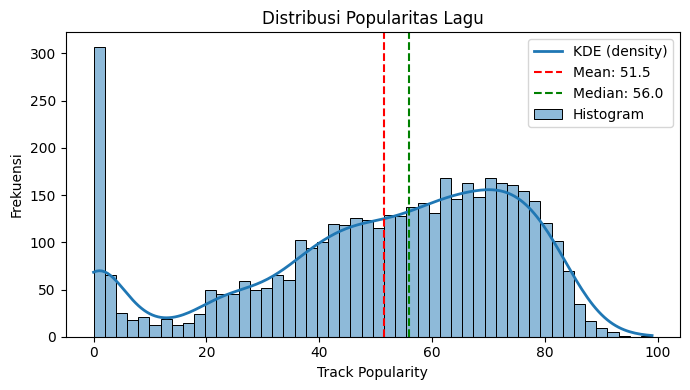

In [63]:
plt.figure(figsize=(7, 4))
sns.histplot(df['track_popularity'], bins=50, kde=True, label='Histogram',
             line_kws={'label': 'KDE (density)', 'linewidth': 2})
plt.axvline(df['track_popularity'].mean(), color='red', linestyle='--',
            label=f"Mean: {df['track_popularity'].mean():.1f}")
plt.axvline(df['track_popularity'].median(), color='green', linestyle='--',
            label=f"Median: {df['track_popularity'].median():.1f}")
plt.title('Distribusi Popularitas Lagu')
plt.xlabel('Track Popularity')
plt.ylabel('Frekuensi')
plt.legend()
plt.tight_layout()
plt.show()

Dari grafik kelihatan kalau sebaran popularitas lagunya agak timpang karena numpuk banget di angka 0 (sampai 300 lagu lebih), yang kemungkinan besar itu lagu-lagu baru atau yang emang sepi pendengar. Tapi buat lagu-lagu yang lain, sebarannya lumayan nyebar di kisaran nilai 40 sampai 80. Makanya nilai tengah (median) ada di 56.0, sedikit lebih tinggi dari rata-rata (mean) yang di angka 51.5, karena rata-ratanya ketarik turun sama lagu-lagu ber-skor nol tadi.

In [65]:
genre_pop = (df.groupby('genre')['track_popularity']
             .agg(avg_pop='mean', jumlah='count')
             .query('jumlah >= 10')
             .sort_values('jumlah', ascending=False)
             .head(15)
             .sort_values('avg_pop')
             .reset_index())

fig = px.bar(genre_pop, x='avg_pop', y='genre', orientation='h',
             color='jumlah', color_continuous_scale='Blues',
             hover_data=['jumlah'],
             title='Rata-rata Popularitas 15 Genre Terbanyak',
             width=700, height=500)

fig.show()

Dari grafik rata-rata popularitas genre, kelompok genre yang berbau latin (reggaeton, trap latino, urbano latino, latin), k-pop, dan rap menduduki posisi teratas dengan skor popularitas rata-rata paling tinggi. Di sisi lain, meskipun genre pop dan soundtrack punya jumlah lagu yang sangat banyak (terlihat dari warna batang yang paling gelap), rata-rata popularitas mereka justru berada di bawah genre latin atau rap.

In [68]:
df_plot = df[df['artist_followers'] > 0].copy()
df_plot['explicit_label'] = df_plot['explicit'].map({True: 'Explicit', False: 'Non-explicit'})

fig = px.scatter(df_plot, x='artist_popularity', y='track_popularity',
                 size='artist_followers', color='explicit_label',
                 opacity=0.5, size_max=25,
                 hover_name='track_name',
                 hover_data=['artist_name', 'artist_followers'],
                 title='Artist Popularity vs Track Popularity (ukuran = followers)',
                 width=750, height=450)

fig.show()

Dari grafik rata-rata popularitas genre, kelompok genre yang berbau latin (reggaeton, trap latino, urbano latino, latin), k-pop, dan rap menduduki posisi teratas dengan skor popularitas rata-rata paling tinggi. Di sisi lain, meskipun genre pop dan soundtrack punya jumlah lagu yang sangat banyak (terlihat dari warna batang yang paling gelap), rata-rata popularitas mereka justru berada di bawah genre latin atau rap.

In [71]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

tren = (df[df['year'] >= 1990].groupby('year')
        .agg(jumlah=('track_id', 'count'), avg_track_pop=('track_popularity', 'mean'),
             avg_artist_pop=('artist_popularity', 'mean'))
        .query('jumlah >= 10').reset_index())

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=tren['year'], y=tren['jumlah'], name='Jumlah lagu', opacity=0.5), secondary_y=False)
fig.add_trace(go.Scatter(x=tren['year'], y=tren['avg_track_pop'], name='Avg track popularity', mode='lines+markers'), secondary_y=True)
fig.add_trace(go.Scatter(x=tren['year'], y=tren['avg_artist_pop'], name='Avg artist popularity', mode='lines+markers'), secondary_y=True)

fig.update_layout(title='Tren Jumlah Rilis dan Popularitas per Tahun', width=750, height=450)
fig.update_yaxes(title_text='Jumlah lagu', secondary_y=False)
fig.update_yaxes(title_text='Rata-rata popularitas', secondary_y=True)
fig.show()

Meskipun jumlah rilis lagu melonjak drastis hingga di atas 300 lagu per tahun dalam satu dekade terakhir, rata-rata popularitas lagu (di kisaran 45–55) dan artis (di kisaran 65–75) justru cenderung stagnan dan tidak ikut naik.